# 🚀 Practice Day 54

**📅 Date:** **2026-11-05**  
**📁 Category:** **Phase 3 · 엔드투엔드 미니 파이프라인 (Round 4/5)**

---
# 🎯 Today's Goal
*What am I trying to solve today?*

- Run a full mini pipeline end to end — clean two messy tables, merge them, then analyze and visualize the result
  (지저분한 테이블 2개를 정제하고 병합한 뒤 분석·시각화까지 전체 파이프라인을 한 번에 진행하기)
- Find which bike type earns the most, what the average ride length is, and which bike gets ridden the most
  (어떤 자전거 유형이 매출을 가장 많이 내는지, 평균 대여시간은 얼마인지, 가장 많이 이용된 자전거는 무엇인지 파악하기)

---
# 📂 Dataset

**Dataset Name:** SpinCycle Bike Share — Bikes & Rides (2 tables) / SpinCycle 자전거 공유서비스 — 자전거·대여기록 (2테이블)

**Source:** Synthetically generated for practice / 실습을 위해 코드로 생성한 가상 데이터

**Description:** Two messy tables. `bikes` (30 rows: bike_id, bike_type) has inconsistent capitalization/whitespace in `bike_type`, plus a couple of missing values. `rides` (~311 rows: ride_id, bike_id → links to bikes, ride_date, ride_minutes, cost) has missing cost, missing ride_date, and some exact duplicate rows. Costs are in USD. The core of this file is cleaning both tables, then merging them for analysis.
(지저분한 테이블 2개입니다. `bikes`(30대: bike_id, bike_type)는 bike_type 표기가 대소문자·공백 등으로 일관되지 않고 일부는 결측치입니다. `rides`(약 311건: ride_id, bike_id(bikes와 연결), ride_date, ride_minutes, cost)는 cost 결측, ride_date 결측, 완전 중복행을 포함합니다. 요금은 USD입니다. 두 테이블을 각각 정제한 뒤 병합해서 분석하는 것이 이 파일의 핵심입니다.)

## Dataset Preview

In [1]:
# Dataset Preview
import pandas as pd
import numpy as np
from IPython.display import display

np.random.seed(42)
rng = np.random.default_rng(42)

# --- bikes (messy: inconsistent bike_type text, a couple missing) ---
bike_types = ['Standard', 'Electric', 'Cargo']
rate_per_min = {'Standard': 0.10, 'Electric': 0.18, 'Cargo': 0.15}  # USD per minute
type_w = [0.55, 0.35, 0.10]

n_bikes = 30
bike_type_assign = rng.choice(bike_types, size=n_bikes, p=type_w)
bikes = pd.DataFrame({
    'bike_id': [f'BK{str(i).zfill(3)}' for i in range(1, n_bikes + 1)],
    'bike_type': bike_type_assign
})
bikes['bike_type'] = bikes['bike_type'].astype(object)

mess_idx = rng.choice(bikes.index, size=int(n_bikes * 0.4), replace=False)
for i in mess_idx:
    base = bikes.loc[i, 'bike_type']
    bikes.loc[i, 'bike_type'] = rng.choice([base.lower(), base.upper(), ' ' + base, base + ' '])

miss_idx = rng.choice(bikes.index, size=2, replace=False)
bikes.loc[miss_idx, 'bike_type'] = np.nan

# --- rides (messy: missing cost, missing ride_date, duplicate rows) ---
n_rides = 300
clean_type_map = dict(zip(bikes['bike_id'], bike_type_assign))
bike_choice = rng.choice(bikes['bike_id'].values, size=n_rides, replace=True)
ride_dates = pd.to_datetime('2024-01-01') + pd.to_timedelta(rng.integers(0, 180, size=n_rides), unit='D')
ride_minutes = np.clip(rng.exponential(18, n_rides), 3, 120).round().astype(int)

rows = []
for i in range(n_rides):
    bid = bike_choice[i]
    bt = clean_type_map[bid]
    noise = rng.normal(1.0, 0.06)
    cost = round(rate_per_min[bt] * ride_minutes[i] * noise, 1)
    rows.append({'ride_id': f'RD{str(i+1).zfill(4)}', 'bike_id': bid, 'ride_date': ride_dates[i],
                 'ride_minutes': int(ride_minutes[i]), 'cost': cost})
rides = pd.DataFrame(rows)

miss_cost_idx = rng.choice(rides.index, size=13, replace=False)
rides.loc[miss_cost_idx, 'cost'] = np.nan

avail_idx = rides.index.difference(miss_cost_idx)
miss_date_idx = rng.choice(avail_idx, size=8, replace=False)
rides.loc[miss_date_idx, 'ride_date'] = pd.NaT

dupe_rows = rides.sample(n=11, random_state=7)
rides = pd.concat([rides, dupe_rows], ignore_index=True)
rides = rides.sample(frac=1, random_state=99).reset_index(drop=True)

print("Bikes:")
display(bikes.head())
print("\nRides:")
display(rides.head())


Bikes:


,bike_id,bike_type
0,BK001,Electric
1,BK002,Standard
2,BK003,electric
3,BK004,Electric
4,BK005,Standard



Rides:


,ride_id,bike_id,ride_date,ride_minutes,cost
0,RD0200,BK014,2024-05-20,5,0.9
1,RD0114,BK022,NaT,9,0.9
2,RD0274,BK020,2024-04-20,32,5.4
3,RD0178,BK015,2024-03-08,18,1.7
4,RD0003,BK025,2024-06-28,15,2.8


## Dataset Information

In [2]:
# Dataset Information
print("Bikes:", bikes.shape)
bikes.info()
print("\nRides:", rides.shape)
rides.info()

print("\n--- Describe: Bikes ---")
display(bikes.describe(include='all'))
print("\n--- Describe: Rides ---")
display(rides.describe(include='all'))


Bikes: (30, 2)
<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   bike_id    30 non-null     str   
 1   bike_type  28 non-null     object
dtypes: object(1), str(1)
memory usage: 612.0+ bytes

Rides: (311, 5)
<class 'pandas.DataFrame'>
RangeIndex: 311 entries, 0 to 310
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   ride_id       311 non-null    str           
 1   bike_id       311 non-null    str           
 2   ride_date     303 non-null    datetime64[us]
 3   ride_minutes  311 non-null    int64         
 4   cost          298 non-null    float64       
dtypes: datetime64[us](1), float64(1), int64(1), str(2)
memory usage: 12.3 KB

--- Describe: Bikes ---


,bike_id,bike_type
count,30,28
unique,30,11
top,BK001,Electric
freq,1,10



--- Describe: Rides ---


,ride_id,bike_id,ride_date,ride_minutes,cost
count,311,311,303,311.00000,298.000000
unique,300,30,NaN,NaN,NaN
top,RD0178,BK014,NaN,NaN,NaN
freq,2,16,NaN,NaN,NaN
mean,NaN,NaN,2024-04-02 02:46:20.198019,20.18328,2.926174
min,NaN,NaN,2024-01-02 00:00:00,3.00000,0.300000
25%,NaN,NaN,2024-02-14 12:00:00,6.00000,0.800000
50%,NaN,NaN,2024-04-04 00:00:00,14.00000,1.800000
75%,NaN,NaN,2024-05-21 00:00:00,27.00000,3.800000
max,NaN,NaN,2024-06-28 00:00:00,111.00000,19.700000


---
# ❓ Business Questions

1. **(Analysis)** After cleaning and merging, which bike type generated the most total rental revenue, and which the least?
   (정제·병합 후, 어떤 자전거 유형이 가장 많은/적은 대여매출을 냈는가?)
2. **(Analysis)** What is the average ride duration (in minutes) across all rides?
   (전체 대여의 평균 이용시간은?)
3. **(Analysis)** Which specific bike has been ridden the most times, and how many times?
   (가장 많이 이용된 자전거는 무엇이며, 몇 번 이용되었는가?)
4. **(Visualization)** Compare total revenue across all bike types.
   (자전거 유형별 총매출을 비교하면?)
5. **(Visualization)** Show how the number of rides moves month to month.
   (월별 이용건수는 어떻게 변화하는가?)

---
# 🔍 Data Cleaning Check


In [3]:
# Data Cleaning Check — inspect only. Fixes are in Q1–Q3.
# (확인만. 수정은 Q1~Q3)

print("===== bikes =====")
print("Missing values")
print(bikes.isnull().sum())
print("\nDuplicate rows:", bikes.duplicated().sum())
print("\nDtypes")
print(bikes.dtypes)
print("\nColumn names")
print(bikes.columns.tolist())
obj_cols = bikes.select_dtypes(include=["object", "string"]).columns
print("\nText columns — unique counts")
print(bikes[obj_cols].nunique())
print()

print("===== rides =====")
print("Missing values")
print(rides.isnull().sum())
print("\nDuplicate rows:", rides.duplicated().sum())
print("\nDtypes")
print(rides.dtypes)
print("\nColumn names")
print(rides.columns.tolist())
obj_cols = rides.select_dtypes(include=["object", "string"]).columns
print("\nText columns — unique counts")
print(rides[obj_cols].nunique())
print()


===== bikes =====
Missing values
bike_id      0
bike_type    2
dtype: int64

Duplicate rows: 0

Dtypes
bike_id         str
bike_type    object
dtype: object

Column names
['bike_id', 'bike_type']

Text columns — unique counts
bike_id      30
bike_type    11
dtype: int64

===== rides =====
Missing values
ride_id          0
bike_id          0
ride_date        8
ride_minutes     0
cost            13
dtype: int64

Duplicate rows: 11

Dtypes
ride_id                    str
bike_id                    str
ride_date       datetime64[us]
ride_minutes             int64
cost                   float64
dtype: object

Column names
['ride_id', 'bike_id', 'ride_date', 'ride_minutes', 'cost']

Text columns — unique counts
ride_id    300
bike_id     30
dtype: int64



---
# 📊 Analysis

## Question 1

**Question:** After cleaning and merging, which bike type generated the most total rental revenue, and which the least? (정제·병합 후 최고·최저 매출 유형은?)

**Result:** Electric generated the most revenue at **$510.10**. Cargo generated the least at **$61.00**. The gap is **$449.10**.  
(매출 1위는 Electric $510.10, 맨 아래는 Cargo $61.00. 차이는 $449.10)

**Insight:** Standard is next at **$212.00**, which is **$298.10** below Electric. The three types add to **$783.10**. **24** merged rides have no bike type, so they are not in these sums.  
(다음은 Standard $212.00으로 Electric보다 $298.10 적음. 세 유형을 더하면 $783.10. 병합 후 유형이 없는 대여가 24건이라 이 합계에 들어가지 않음)

In [4]:
# Question 1: total revenue by bike_type (after cleaning + merging)
bikes['bike_type'].unique()

array(['Electric', 'Standard', np.str_('electric'), np.str_('CARGO'), nan,
       np.str_('Standard '), 'Cargo', np.str_(' Electric'),
       np.str_('STANDARD'), np.str_(' Standard'), np.str_('Cargo '),
       np.str_('Electric ')], dtype=object)

In [5]:
cleaned_bikes = bikes.copy()

cleaned_bikes['bike_type'] = cleaned_bikes['bike_type'].str.strip()
cleaned_bikes['bike_type'] = cleaned_bikes['bike_type'].str.title()

cleaned_bikes['bike_type'].unique()

array(['Electric', 'Standard', 'Cargo', nan], dtype=object)

In [6]:
cleaned_rides = rides.copy()
cleaned_rides.drop_duplicates(inplace=True)

cleaned_rides.duplicated().sum()

np.int64(0)

In [7]:
merged_df = cleaned_rides.merge(cleaned_bikes, on='bike_id', how='left')

print(merged_df.info())
print(merged_df.duplicated().sum())
merged_df.head()

<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   ride_id       300 non-null    str           
 1   bike_id       300 non-null    str           
 2   ride_date     292 non-null    datetime64[us]
 3   ride_minutes  300 non-null    int64         
 4   cost          287 non-null    float64       
 5   bike_type     276 non-null    object        
dtypes: datetime64[us](1), float64(1), int64(1), object(1), str(2)
memory usage: 14.2+ KB
None
0


,ride_id,bike_id,ride_date,ride_minutes,cost,bike_type
0,RD0200,BK014,2024-05-20,5,0.9,Electric
1,RD0114,BK022,NaT,9,0.9,Standard
2,RD0274,BK020,2024-04-20,32,5.4,Electric
3,RD0178,BK015,2024-03-08,18,1.7,Standard
4,RD0003,BK025,2024-06-28,15,2.8,Electric


In [8]:
merged_df.groupby('bike_type')['cost'].sum().sort_values(ascending=False)

bike_type
Electric    510.1
Standard    212.0
Cargo        61.0
Name: cost, dtype: float64

## Question 2

**Question:** What is the average ride duration (in minutes) across all rides? (전체 평균 이용시간은?)

**Result:** The average ride lasts **20.14** minutes.  
(평균 이용시간은 20.14분)

**Insight:** This is the mean of all **300** rides after the **11** exact duplicates were removed.  
(정확히 같은 중복 11건을 지운 뒤 300건 전체의 평균)

In [9]:
# Question 2: average ride duration across all rides
merged_df['ride_minutes'].sum() / merged_df['ride_minutes'].count()

np.float64(20.143333333333334)

## Question 3

**Question:** Which specific bike has been ridden the most times, and how many times? (가장 많이 이용된 자전거와 횟수는?)

**Result:** Bike **BK014** has been ridden the most, **16** times.  
(가장 많이 이용된 자전거는 BK014, 16회)

**Insight:** **BK005** and **BK024** follow at **14** each, which is **2** below BK014. **BK009** and **BK020** have **13** each.  
(BK005와 BK024가 각각 14회로 BK014보다 2회 적음. BK009와 BK020은 각각 13회)

In [10]:
# Question 3: most-ridden bike (by ride count)
merged_df.groupby('bike_id')['ride_id'].count().sort_values(ascending=False).head(5)

bike_id
BK014    16
BK005    14
BK024    14
BK009    13
BK020    13
Name: ride_id, dtype: int64

---
# 📈 Visualization

**Chart 1:** Bar chart — total revenue by bike type (막대그래프: 자전거 유형별 총매출)

*Interpretation:* The bars follow the revenue table: Electric **$510.10**, Standard **$212.00**, Cargo **$61.00**.  
(막대는 매출 표 순서. Electric $510.10, Standard $212.00, Cargo $61.00)

---

**Chart 2:** Line chart — monthly ride count (선그래프: 월별 이용건수 추이)

*Interpretation:* Rides are **52** in January and **43** in March, the lowest month. May is **52** and June is **51**. The gap between the highest and lowest month is **9**.  
(1월 52건, 가장 낮은 달은 3월 43건. 5월 52건, 6월 51건. 가장 많은 달과 적은 달의 차이는 9건)

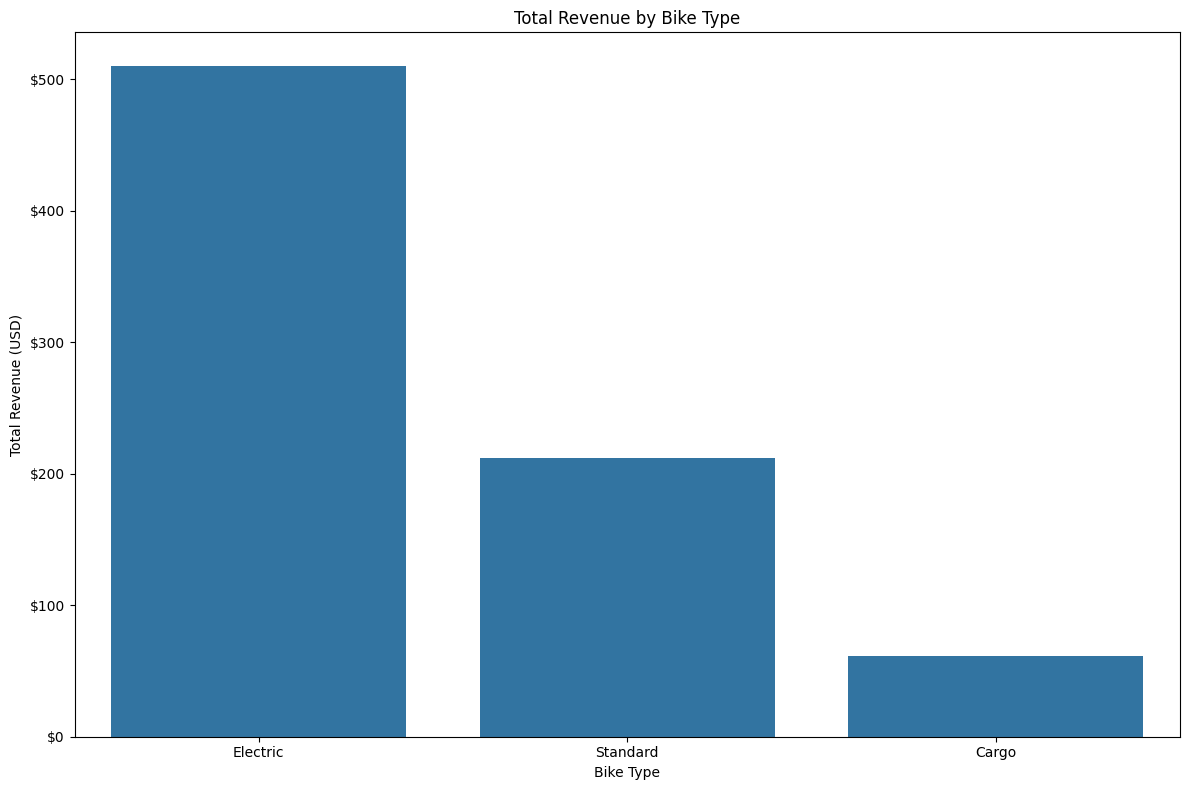

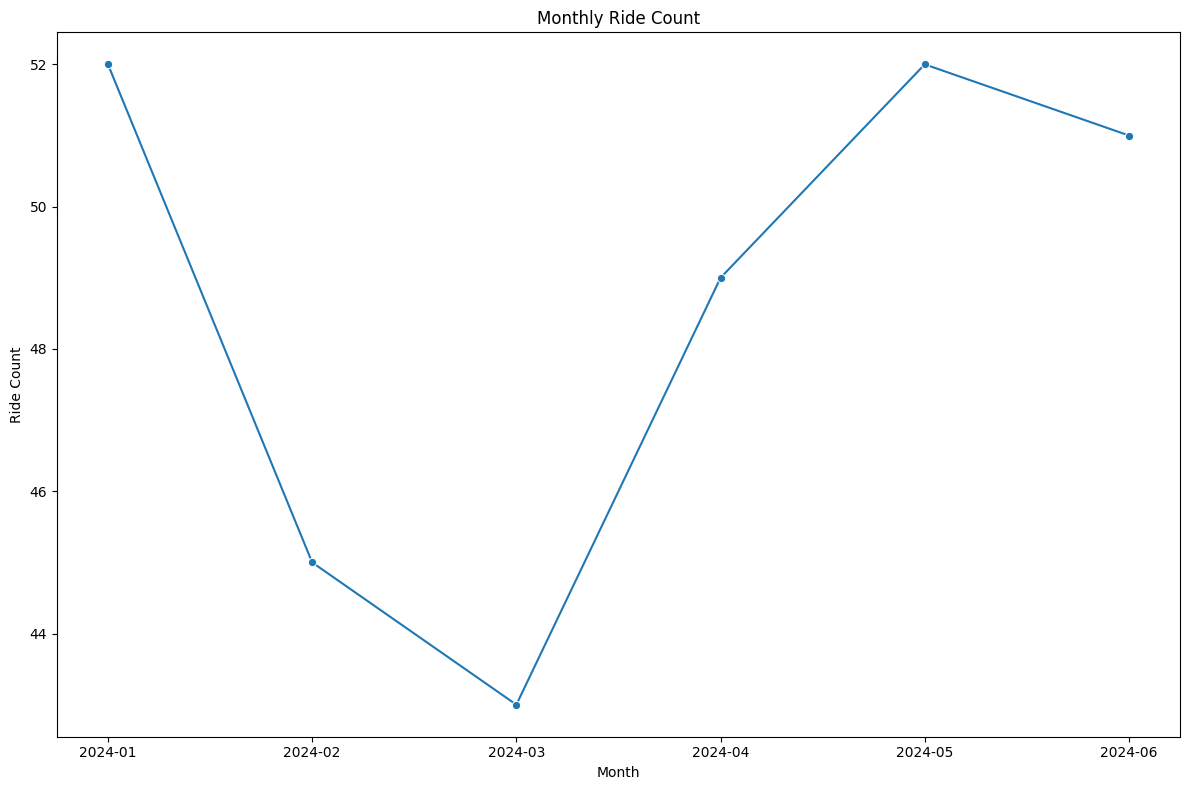

In [11]:
# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Chart 1: total revenue by bike_type (bar)
# Same order as the Q1 table (rides with a missing bike_type or cost are not in the sum)
revenue_by_type = merged_df.groupby('bike_type')['cost'].sum().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(12, 8))
sns.barplot(x=revenue_by_type.index, y=revenue_by_type.values, errorbar=None, ax=ax)
ax.yaxis.set_major_formatter('${x:,.0f}')
ax.set_title('Total Revenue by Bike Type')
ax.set_xlabel('Bike Type')
ax.set_ylabel('Total Revenue (USD)')
plt.tight_layout()
plt.show()

# Chart 2: monthly ride count (line)
# Rides with a missing ride_date are left out of the monthly count
monthly_rides = merged_df.groupby(merged_df['ride_date'].dt.to_period('M'))['ride_id'].count()

fig, ax = plt.subplots(figsize=(12, 8))
sns.lineplot(x=monthly_rides.index.astype(str), y=monthly_rides.values, marker='o', ax=ax)
ax.set_title('Monthly Ride Count')
ax.set_xlabel('Month')
ax.set_ylabel('Ride Count')
plt.tight_layout()
plt.show()

---
# 💼 Business Insights
*What did I discover?*

- Electric earns the most at **$510.10**. Cargo earns the least at **$61.00**.  
  (Electric이 $510.10으로 매출 1위. Cargo는 $61.00으로 맨 아래)
- The average ride is **20.14** minutes. BK014 is the most-ridden bike at **16** rides.  
  (평균 이용시간은 20.14분. 가장 많이 이용된 자전거는 BK014, 16회)
- Monthly rides range from **43** in March to **52** in January and May.  
  (월별 이용건수는 3월 43건에서 1월·5월 52건 사이)  

---
# 🎯 Business Recommendation
*If I were the Business Analyst...*

1. Treat Electric as the revenue leader. Its **$510.10** is **$298.10** above Standard.  
   (Electric을 매출 중심으로 볼 것. $510.10은 Standard보다 $298.10 많음)
2. Fix the bike type for the **24** rides that have none before the next revenue report.  
   (유형이 없는 대여 24건은 다음 매출 보고 전에 채워 둘 것)
3. Watch the March dip to **43** rides against **52** in January.  
   (1월 52건에 비해 3월 43건으로 내려간 구간을 볼 것)  

---
# ❌ Mistakes
*What mistakes did I make today?*

- The charts had no title and no axis titles at first.  
  (처음에는 차트에 제목과 축 제목이 없었음)
- Chart 1 drew the bars in data order, not in the revenue table order.  
  (Chart 1은 막대를 매출 표 순서가 아니라 데이터 순서로 그렸음)  

---
# ✅ What I Learned
*Today's biggest lesson*

- `.str.strip()` then `.str.title()` turns the **11** spellings of `bike_type` into Electric, Standard, and Cargo.  
  (`.str.strip()` 다음 `.str.title()`로 `bike_type` 표기 11개가 Electric, Standard, Cargo로 정리됨)
- `drop_duplicates()` before `merge(..., how='left')` keeps **300** rides.  
  (`drop_duplicates()` 뒤에 `merge(..., how='left')`하면 대여 300건이 그대로 유지됨)
- `groupby('bike_type')['cost'].sum()` skips rides whose bike type or cost is missing.  
  (`groupby('bike_type')['cost'].sum()`은 유형이나 요금이 없는 대여를 빼고 더함)  

---
# 🧠 Reflection

**What was difficult?**  
Keeping the bar order and the labels the same as the analysis table.  
(막대 순서와 라벨을 분석 표와 같게 맞추는 것)

**Why?**  
`sns.barplot` on the merged rows draws the types in data order and adds no titles.  
(병합한 행을 그대로 `sns.barplot`에 넣으면 유형이 데이터 순서로 그려지고 제목도 없음)

**How did I solve it?**  
Plotted the sorted `groupby` sum and added a title, axis titles, and a USD axis.  
(정렬된 `groupby` 합계를 그리고 제목, 축 제목, USD 축을 붙임)

**What would I do differently next time?**  
Add the chart title and axis titles when I first draw the chart.  
(차트를 처음 그릴 때 제목과 축 제목을 같이 넣기)

---
# ⭐ Self Evaluation

**Understanding**  
★★★★★★★★☆☆  
The cleaning, the merge, and the three groupbys match the questions. Electric earns **$510.10** and BK014 has **16** rides.  
(정제, 병합, groupby 세 개가 질문과 맞음. Electric 매출 $510.10, BK014는 16회)

**Confidence**  
★★★★★★★☆☆☆  

**Difficulty**  
★★★★☆☆☆☆☆☆  
The pipeline steps were short. The chart labels and bar order took the extra work.  
(파이프라인 단계는 짧았음. 차트 라벨과 막대 순서에 손이 더 갔음)

---
# 📌 Tomorrow
*Tomorrow I will learn:*

- Practice Day 55 — Pandas basics (Round 4/5)  
  (Pandas 기초로 표를 읽고 집계하기)  